In [21]:
%pip install pint matplotlib numpy>=1.25

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
import pandas as pd
import pint
import matplotlib.pyplot as plt
import numpy as np

In [23]:
# from https://github.com/NaturalHistoryMuseum/ADEPT/blob/main/adept/data/assets/anatomical-parts.yml

LEAF_SYNONYMS = [
  'leaf',
  'leaves',
  'leave',
  'blade',
  'blades',
  'underleave',
  'underleaves',
  'underleaf',
  'leaf-blade',
  'leaf blade',
]

UNITS = ['cm', 'mm', 'm', 'in', 'ft', 'inches', 'inch', 'centimetres', 'foot', 'feet', 'metres', 'metre', 'millimetres', 'millimeter', 'millimeters', 'centimeter', 'centimeters']

In [24]:
ureg = pint.UnitRegistry()

def convert_to_unit(value, from_unit, to_unit):
    quantity = value * ureg(from_unit)
    converted = quantity.to(to_unit)
    return converted.magnitude

In [25]:
from tqdm import tqdm

TRAITS_CSV = "extracted_quantities.csv"

traits_df = pd.read_csv(TRAITS_CSV)

traits_df.head()

,entity,property,value_min,value_max,unit,quantity_text,quantity_type,ipni_id,provider
0,relatively large corolla,length,28.0,32.0,mm,28-32 mm,range,77177570-1,Provided by: [ B ]. e-Flora of South Africa
1,large corolla,length,20.0,20.0,-25 (-27) mm,20-25(-27) mm,single_quantity,77177570-1,Provided by: [ B ]. e-Flora of South Africa
2,bracts,length,5.0,5.0,fid,5-fid,single_quantity,77177569-1,Provided by: [ B ]. e-Flora of South Africa
3,staminodes,length,0.7,0.7,mm,0.7 mm,single_quantity,770599-1,Provided by: [ A ]. e-Flora of South Africa
4,leaves,number of gland dots,2.0,2.0,rows of gland dots,two rows of gland dots,single_quantity,770599-1,Provided by: [ A ]. e-Flora of South Africa


In [26]:
leaf_traits_df = traits_df[traits_df['entity'].str.lower().isin(LEAF_SYNONYMS)
 & traits_df['property'].str.lower().isin(['length', 'width'])
 & traits_df['quantity_type'].str.lower().isin(['single_quantity', 'range'])
 & traits_df['unit'].str.lower().isin(UNITS)]

print(f"Found these units in dataset: {sorted(leaf_traits_df['unit'].dropna().unique())}")

leaf_traits_df["converted_min"] = [
    convert_to_unit(v, u, 'mm')
    for v, u in zip(
        leaf_traits_df["value_min"],
        leaf_traits_df["unit"],
    )
]

leaf_traits_df["converted_max"] = [
    convert_to_unit(v, u, 'mm')
    for v, u in zip(
        leaf_traits_df["value_max"],
        leaf_traits_df["unit"],
    )
]

leaf_traits_df.head()

Found these units in dataset: ['cm', 'ft', 'in', 'inch', 'inches', 'm', 'millimeter', 'mm']


C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\2194053481.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf_traits_df["converted_min"] = [
C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\2194053481.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf_traits_df["converted_max"] = [


,entity,property,value_min,value_max,unit,quantity_text,quantity_type,ipni_id,provider,converted_min,converted_max
22,leaves,width,10.0,10.0,mm,10 mm,single_quantity,837437-1,Provided by: [ B ]. e-Flora of South Africa,10.0,10.0
125,Leaves,length,3.0,3.0,in,3 in,single_quantity,178578-1,Provided by: [ B ]. e-Flora of South Africa,76.2,76.2
126,Leaves,width,0.5,0.5,in,1/2 in,single_quantity,178578-1,Provided by: [ B ]. e-Flora of South Africa,12.7,12.7
135,leaves,width,2.0,2.0,mm,2 mm,single_quantity,77067007-1,Provided by: [ A ]. e-Flora of South Africa,2.0,2.0
146,leaves,width,9.0,9.0,mm,9 mm,single_quantity,435969-1,Provided by: [ A ]. e-Flora of South Africa,9.0,9.0


In [27]:
#TODO: investigate max length of 500600
leaf_traits_df[leaf_traits_df['property'] == 'length'].describe()

,value_min,value_max,converted_min,converted_max
count,827.000000,827.000000,827.000000,827.000000
mean,1360.776747,1373.150826,1457.461025,1512.726018
std,22806.032916,22805.427832,22801.994168,22800.152656
min,0.100000,0.100000,0.200000,0.200000
25%,2.100000,5.000000,6.000000,10.000000
50%,6.000000,12.000000,25.000000,60.000000
75%,20.000000,35.000000,100.000000,200.000000
max,500600.000000,500600.000000,500600.000000,500600.000000


In [28]:
leaf_traits_df[leaf_traits_df['property'] == 'width'].describe()

,value_min,value_max,converted_min,converted_max
count,602.000000,602.000000,602.000000,602.000000
mean,6.703040,11.995482,18.847924,32.886601
std,15.300741,26.461362,34.134634,46.569538
min,0.100000,0.220000,0.200000,0.500000
25%,1.000000,2.225000,2.000000,4.000000
50%,2.450000,5.000000,6.000000,13.000000
75%,6.000000,10.000000,20.000000,45.000000
max,200.000000,350.000000,350.000000,350.000000


C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\3288726734.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  width_range_df["midpoint"] = (width_range_df["value_min"] + width_range_df["value_max"]) / 2
C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\3288726734.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  width_range_df["width"] = width_range_df["value_max"] - width_range_df["value_min"]


Text(0, 0.5, 'Range width (mm)')

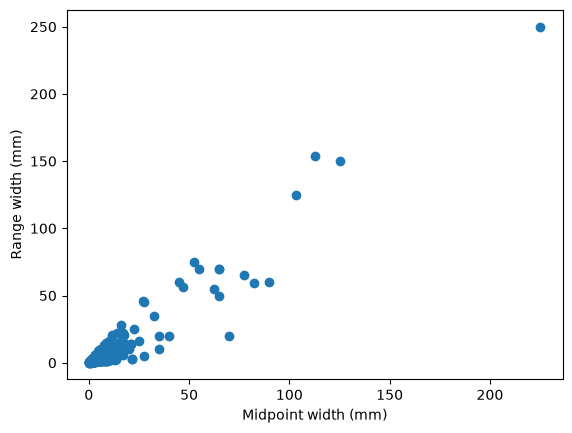

In [32]:
width_range_df = leaf_traits_df[(leaf_traits_df['quantity_type'].str.lower() == 'range') & (leaf_traits_df['property'] == 'width')]

width_range_df["midpoint"] = (width_range_df["value_min"] + width_range_df["value_max"]) / 2
width_range_df["width"] = width_range_df["value_max"] - width_range_df["value_min"]

plt.scatter(width_range_df["midpoint"], width_range_df["width"])
plt.xlabel("Midpoint width (mm)")
plt.ylabel("Range width (mm)")

In [30]:
heights_df = traits_df[
    (traits_df['property'].str.lower() == 'height') &
    (traits_df['quantity_type'].str.lower().isin(['single_quantity', 'range'])) &
    (traits_df['unit'].str.lower().isin(UNITS))
]

print(f"Found these units in dataset: {sorted(heights_df['unit'].dropna().unique())}")

heights_df["converted_min"] = [
    convert_to_unit(v, u, 'cm')
    for v, u in zip(
        heights_df["value_min"],
        heights_df["unit"],
    )
]

heights_df["converted_max"] = [
    convert_to_unit(v, u, 'cm')
    for v, u in zip(
        heights_df["value_max"],
        heights_df["unit"],
    )
]

heights_df.head()

Found these units in dataset: ['cm', 'feet', 'foot', 'ft', 'in', 'inches', 'm', 'metre', 'metres', 'mm']


C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\3895748627.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  heights_df["converted_min"] = [
C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\3895748627.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  heights_df["converted_max"] = [


,entity,property,value_min,value_max,unit,quantity_text,quantity_type,ipni_id,provider,converted_min,converted_max
29,Plants,height,9.0,12.0,ft,9-12 ft,range,529197-1,Provided by: [ B ]. e-Flora of South Africa,274.32,365.76
38,A. comosa,height,6.0,8.0,ft,6-8 ft,range,529337-1,Provided by: [ B ]. e-Flora of South Africa,182.88,243.84
40,procumbent stem,height,6.0,6.0,ft,6 ft,single_quantity,529341-1,Provided by: [ B ]. e-Flora of South Africa,182.88,182.88
41,inflorescence,height,3.0,3.0,ft,3 ft,single_quantity,529341-1,Provided by: [ B ]. e-Flora of South Africa,91.44,91.44
74,Young simple-stemmed plants,height,1.8,2.7,m,1.8-2.7 m,range,77125492-1,Provided by: [ B ]. e-Flora of South Africa,180.00,270.00


C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\1197938531.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  height_range_df["midpoint"] = (height_range_df["value_min"] + height_range_df["value_max"]) / 2
C:\Users\3265458R\AppData\Local\Temp\ipykernel_37904\1197938531.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  height_range_df["width"] = height_range_df["value_max"] - height_range_df["value_min"]


Text(0, 0.5, 'Range width (m)')

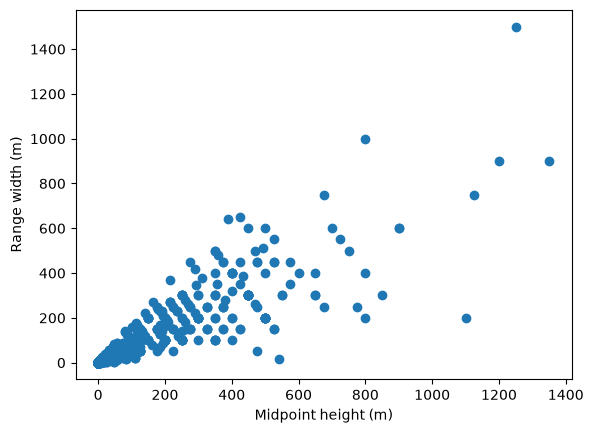

In [31]:
height_range_df = heights_df[heights_df['quantity_type'].str.lower() == 'range']

height_range_df["midpoint"] = (height_range_df["value_min"] + height_range_df["value_max"]) / 2
height_range_df["width"] = height_range_df["value_max"] - height_range_df["value_min"]

plt.scatter(height_range_df["midpoint"], height_range_df["width"])
plt.xlabel("Midpoint height (m)")
plt.ylabel("Range width (m)")

In [36]:
def calculate_unique_populated_traits_per_species(df):
    return df.groupby('ipni_id')['property'].nunique().reset_index(name='populated_traits_count')

print(calculate_unique_populated_traits_per_species(traits_df).describe())

       populated_traits_count
count             2809.000000
mean                 6.146671
std                  4.655266
min                  1.000000
25%                  2.000000
50%                  5.000000
75%                  9.000000
max                 35.000000


In [48]:
def calculate_leaf_and_height_traits_per_species(leaf_df, height_df, ipni_id, species_name):
    has_leaf_width = not leaf_df[(leaf_df['ipni_id'] == ipni_id) & (leaf_df['property'] == 'width')].empty
    has_leaf_length = not leaf_df[(leaf_df['ipni_id'] == ipni_id) & (leaf_df['property'] == 'length')].empty
    has_height = not height_df[(height_df['ipni_id'] == ipni_id) & (height_df['property'] == 'height')].empty   

    return pd.DataFrame({
        'ipni_id': [ipni_id],
        'species_name': [species_name],
        'has_leaf_width': [has_leaf_width],
        'has_leaf_length': [has_leaf_length],
        'has_height': [has_height],
    })

PLANTS_CSV = "plants_with_taxonomy.csv"

plants_df = pd.read_csv(PLANTS_CSV)

populated_traits_per_species_df = pd.concat([
    calculate_leaf_and_height_traits_per_species(leaf_traits_df, heights_df, ipni_id, species_name)
    for ipni_id, species_name in tqdm(zip(plants_df['ipni_id'], plants_df['taxon_name']), total=len(plants_df))
])

populated_traits_per_species_df.head()

100%|██████████| 11790/11790 [00:10<00:00, 1137.43it/s]


,ipni_id,species_name,has_leaf_width,has_leaf_length,has_height
0,261601-1,Abies numidica,False,False,False
0,77175637-1,Abrahamia buxifolia,False,False,False
0,77175641-1,Abrahamia deflexa,False,False,False
0,77175646-1,Abrahamia ditimena,False,False,False
0,77175648-1,Abrahamia ellipticarpa,False,False,False


In [47]:
populated_traits_per_species_df[populated_traits_per_species_df['has_leaf_width'] == True].describe()

,ipni_id,species_name,has_leaf_width,has_leaf_length,has_height
count,497,497,497,497,497
unique,497,497,1,2,2
top,337354-1,Acalypha echinus,True,True,True
freq,1,1,497,305,392


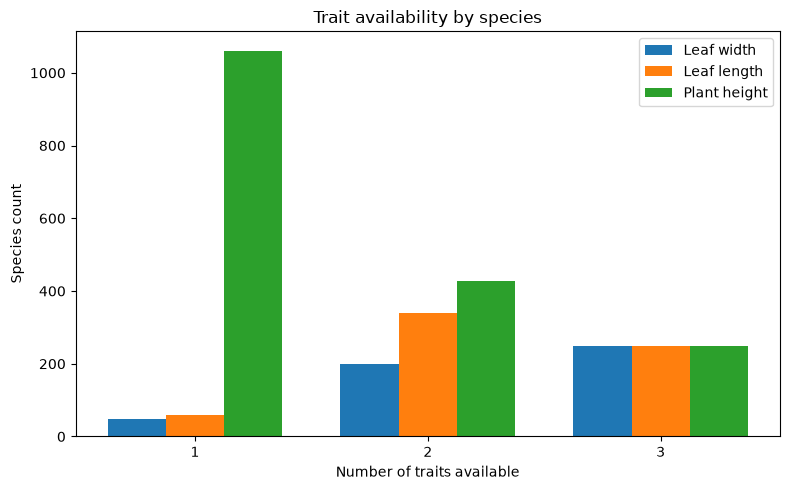

In [51]:
trait_cols = [
    "has_leaf_width",
    "has_leaf_length",
    "has_height",
]

populated_traits_per_species_df["n_traits"] = (
    populated_traits_per_species_df[trait_cols]
    .sum(axis=1)
)

counts = (
    populated_traits_per_species_df
    .groupby("n_traits")[trait_cols]
    .sum()
    .loc[[1, 2, 3]]
)

x = np.arange(len(counts.index))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(x - width, counts["has_leaf_width"], width, label="Leaf width")
ax.bar(x, counts["has_leaf_length"], width, label="Leaf length")
ax.bar(x + width, counts["has_height"], width, label="Plant height")

ax.set_xticks(x)
ax.set_xticklabels(counts.index)
ax.set_xlabel("Number of traits available")
ax.set_ylabel("Species count")
ax.set_title("Trait availability by species")
ax.legend()

plt.tight_layout()
plt.show()

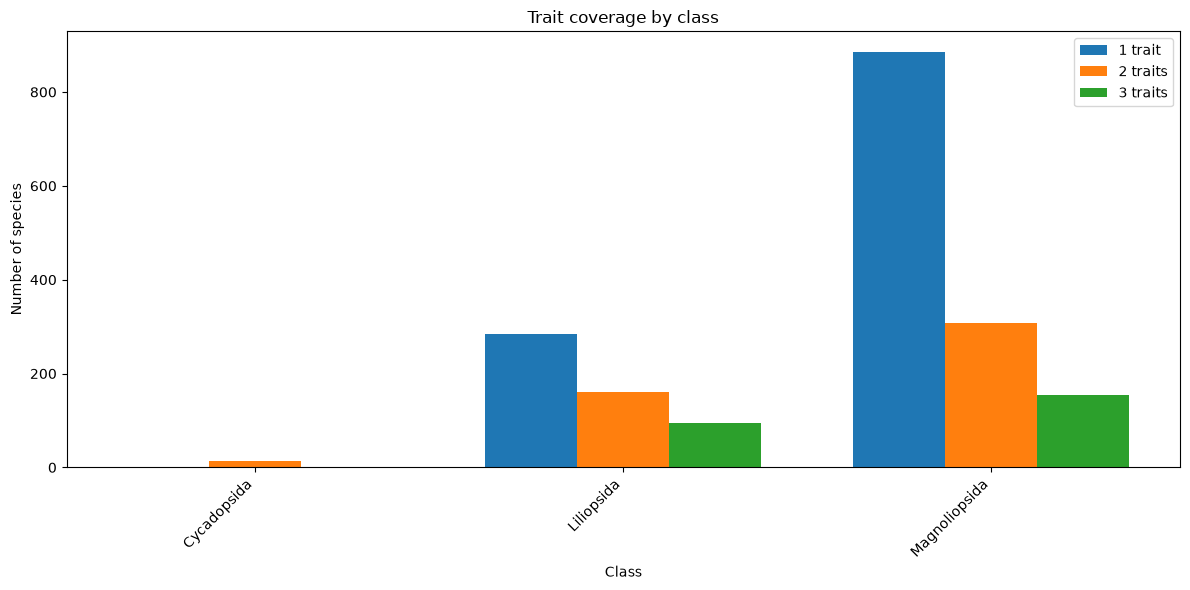

In [54]:
trait_cols = [
    "has_leaf_width",
    "has_leaf_length",
    "has_height",
]

merged_df = populated_traits_per_species_df.merge(
    plants_df[["ipni_id", "class", "order", "family"]],
    on="ipni_id",
    how="left",
)

merged_df["n_traits"] = merged_df[trait_cols].sum(axis=1)

counts = (
    merged_df[merged_df["n_traits"] > 0]
    .groupby(["class", "n_traits"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[1, 2, 3], fill_value=0)
)

x = np.arange(len(counts))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(x - width, counts[1], width, label="1 trait")
ax.bar(x, counts[2], width, label="2 traits")
ax.bar(x + width, counts[3], width, label="3 traits")

ax.set_xticks(x)
ax.set_xticklabels(counts.index, rotation=45, ha="right")

ax.set_ylabel("Number of species")
ax.set_xlabel("Class")
ax.set_title("Trait coverage by class")
ax.legend()

plt.tight_layout()
plt.show()


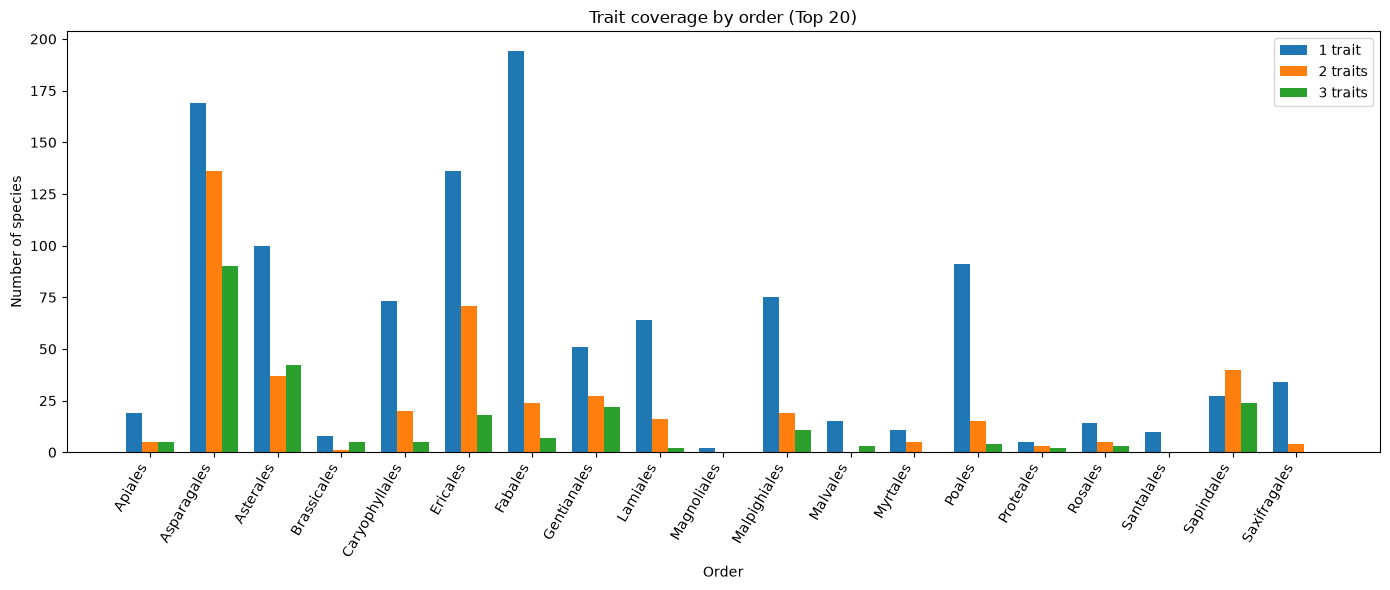

In [56]:
counts = (
    merged_df[merged_df["n_traits"] > 0]
    .groupby(["order", "n_traits"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[1, 2, 3], fill_value=0)
)

top_orders = merged_df["order"].value_counts().head(20).index
counts = counts.loc[counts.index.intersection(top_orders)]

x = np.arange(len(counts))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x - width, counts[1], width, label="1 trait")
ax.bar(x, counts[2], width, label="2 traits")
ax.bar(x + width, counts[3], width, label="3 traits")

ax.set_xticks(x)
ax.set_xticklabels(counts.index, rotation=60, ha="right")

ax.set_ylabel("Number of species")
ax.set_xlabel("Order")
ax.set_title("Trait coverage by order (Top 20)")
ax.legend()

plt.tight_layout()
plt.show()